# 20 — Regímenes y fenómenos: El Niño, La Niña, sismos, crisis de la red

## Qué pidió el propietario

«Marcaste la COVID, pero no las demás catástrofes y fenómenos: El Niño y La Niña, terremotos, epidemias…»

## Cómo se marcan sin sobreajustar (fila `regimenes` de `variables.csv`)

El cuaderno 16 mostró el límite: con 4 episodios de El Niño, un modelo no aprende el efecto; memoriza esos 4.
Por eso cada fenómeno entra como **estado que dura y se repite**, conocido el día de la predicción:

| Estado | Cómo se define | Fuente |
|---|---|---|
| **El Niño / La Niña** | ONI de dos meses antes ≥ +0,5 / ≤ −0,5 (la NOAA lo publica con retraso) | NOAA, capturado cada semana |
| **COVID** fuerte / parcial | 2020-03-15 a 2020-08-31 / hasta 2022-02-28 | fechas fijas |
| **Paro nacional 2021** | 2021-04-28 a 2021-06-15 | fechas fijas |
| **Sismo fuerte** | los 7 días siguientes a un sismo de M ≥ 4,5 a menos de 150 km | USGS (`calendarios/sismos_usgs.csv`) |
| **Desastre activo** | catálogo propio de Manizales | `desastres_manizales_2020_2026.csv` |
| **Crisis de la red** | peso de Nueva EPS en el triage de 28 días por debajo de su percentil 10 de 2022-2024 | triage del hospital |

**Exploración:** sobre las familias de enfermedad de la ciudad (2012-2024) y el triage total (2022-2024),
con mes fijo y **tendencia lineal en lugar de año fijo**: un El Niño dura un año, y el año fijo se lo comería.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from matplotlib import pyplot as plt
import indices as ix
from desenlace import desenlace_semanal
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
R = ix.regimenes_diarios()
ESTADOS = ["el_nino", "la_nina", "covid_fuerte", "covid_parcial", "paro_nacional_2021", "sismo_fuerte_7d", "desastre_activo", "crisis_red"]
def episodios(s):
    s = s.fillna(0) > 0; return int((s & ~s.shift(fill_value=False)).sum())
tab = pd.DataFrame({e: {"episodios 2012-2024": episodios(R[e].loc["2012":"2024"]), "días 2012-2024": int(R[e].loc["2012":"2024"].sum()),
                        "episodios 2020-2024": episodios(R[e].loc["2020":"2024"]), "días 2025-2026": int(R[e].loc["2025":].sum())} for e in ESTADOS}).T
tab

,episodios 2012-2024,días 2012-2024,episodios 2020-2024,días 2025-2026
el_nino,4,1431,2,92
la_nina,5,1061,2,90
covid_fuerte,1,170,1,0
covid_parcial,1,546,1,0
paro_nacional_2021,1,49,1,0
sismo_fuerte_7d,40,289,20,82
desastre_activo,9,466,9,117
crisis_red,4,139,4,294


**Lectura. El tamaño de la muestra lo dice todo.**

- Entre 2012 y 2024 hay **4 episodios de El Niño y 5 de La Niña** (1.431 y 1.061 días), **40 semanas tras un sismo fuerte**, 9 desastres catalogados y 4 crisis de la red.
- **En la ventana del hospital (2020-2024) quedan 2 episodios de cada fase ENSO, y 1 de COVID y 1 de paro nacional.**
- **La COVID y el paro no se pueden aprender:** pasaron una vez. Entran al modelo como **marcas** para que no contaminen lo demás, no para predecir con ellas.
- **Los sismos** son la excepción: con 40 episodios sí hay muestra. **ENSO** tiene poca, y con la historia de la ciudad (2012-2024) llega a 9 episodios.

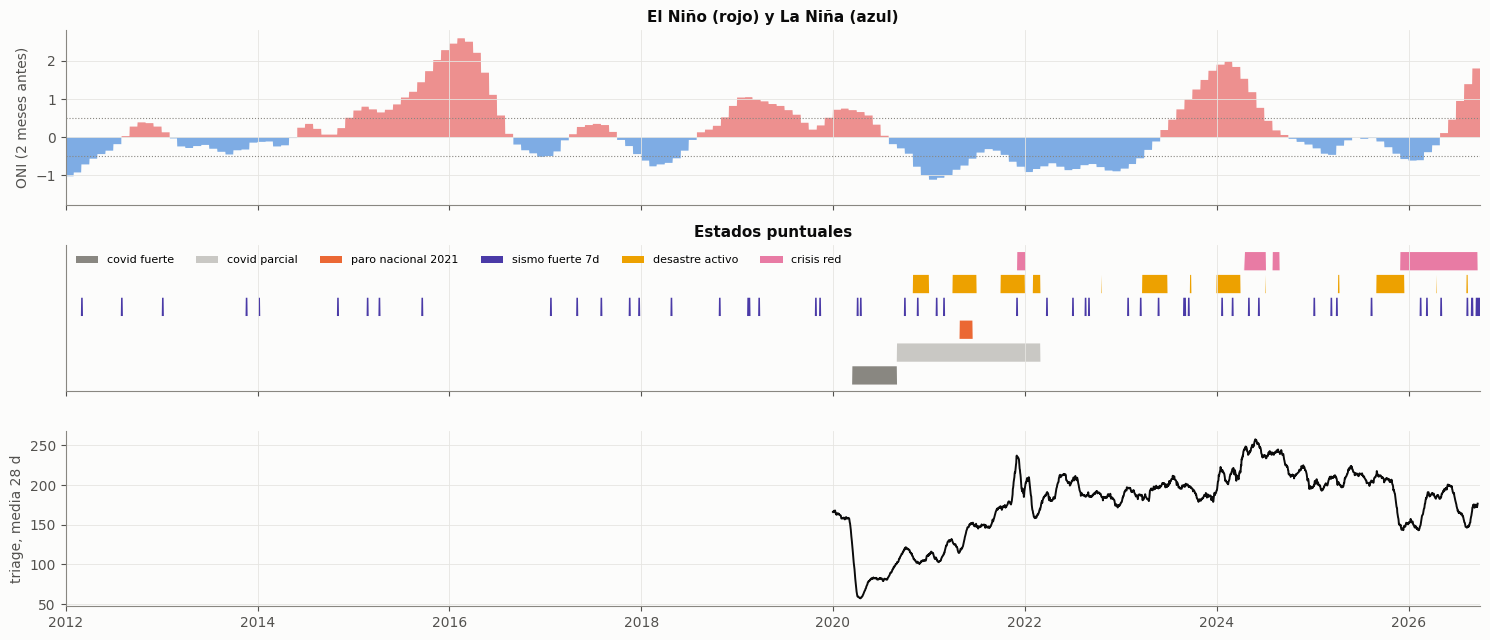

In [2]:
fig, axes = plt.subplots(3, 1, figsize=(15, 6.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1, 1.2]})
axes[0].fill_between(R.index, 0, R.oni, where=R.oni > 0, color=ROJO, alpha=.6, lw=0); axes[0].fill_between(R.index, 0, R.oni, where=R.oni < 0, color=AZUL, alpha=.6, lw=0)
axes[0].axhline(.5, color=MUDO, ls=":", lw=.8); axes[0].axhline(-.5, color=MUDO, ls=":", lw=.8); axes[0].set_ylabel("ONI (2 meses antes)"); axes[0].set_title("El Niño (rojo) y La Niña (azul)")
for i, (e, c) in enumerate([("covid_fuerte", MUDO), ("covid_parcial", "#c9c8c4"), ("paro_nacional_2021", NARANJA), ("sismo_fuerte_7d", VIOLETA), ("desastre_activo", AMARILLO), ("crisis_red", MAGENTA)]):
    axes[1].fill_between(R.index, i, i + R[e].fillna(0) * .8, color=c, lw=0, label=e.replace("_", " "))
axes[1].set_yticks([]); axes[1].legend(ncol=6, fontsize=8, loc="upper left"); axes[1].set_title("Estados puntuales")
t = pd.read_parquet(RAIZ / "salidas/triage_diario.parquet").assign(dia=lambda d: pd.to_datetime(d.dia)).set_index("dia").triages
axes[2].plot(t.index, t.rolling(28, center=True, min_periods=14).mean(), color=TINTA, lw=1.4); axes[2].set_ylabel("triage, media 28 d")
axes[2].set_xlim(pd.Timestamp("2012-01-01"), R.index[-1]); plt.tight_layout(); plt.show()

---
# 1. ¿Mueven los regímenes a las enfermedades de la ciudad? (2012-2024)

Efecto de estar en el estado sobre el índice de cada familia, en desviaciones típicas del índice. ● = sobrevive
a BH (q < 0,10).

In [3]:
FAM = ix.familias_enfermedad().loc["2012":ix.REF_FIN]
W = R[ESTADOS].resample("W-SAT").mean(); W.index -= pd.Timedelta(days=6)
def efecto(y, X):
    filas = []; idx = y.dropna().index
    mes = pd.get_dummies(pd.Index(idx.month), prefix="m", drop_first=True).set_index(idx).astype(float)
    tend = pd.Series(np.arange(len(idx)) / 52, index=idx, name="tendencia")
    for c in X:
        D = pd.concat([y.rename("y"), X[c].rename("x"), mes, tend], axis=1).loc[idx].dropna()
        if D.x.std() == 0 or (D.x > 0).sum() < 4: continue
        r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 8})
        filas.append({"estado": c, "efecto": r.params["x"], "p": r.pvalues["x"], "semanas en el estado": int((D.x > 0).sum())})
    T = pd.DataFrame(filas)
    if len(T): T["q"] = multipletests(T.p, method="fdr_bh")[1]
    return T
RF = {fam: efecto(FAM[fam], W.drop(columns=["crisis_red"])) for fam in FAM}
M = pd.DataFrame({fam: T.set_index("estado")["efecto"] for fam, T in RF.items()}).round(2)
Q = pd.DataFrame({fam: T.set_index("estado")["q"] for fam, T in RF.items()})
M.astype(str).where(Q >= .10, M.astype(str) + " ●")

,respiratoria,digestiva,violencias_y_agresiones,salud_mental_e_intoxicaciones,materno_perinatal,inmunoprevenibles
estado,,,,,,
el_nino,-0.04,-0.08,-0.15,0.01,0.03,-0.07
la_nina,0.29,0.17,0.35 ●,0.31 ●,-0.05,0.38 ●
covid_fuerte,-1.86 ●,-1.79 ●,-1.09 ●,-1.09 ●,0.41 ●,-1.53 ●
covid_parcial,0.21,0.4,0.1,0.22 ●,0.13,0.37
paro_nacional_2021,0.3,-0.36,0.16,0.3,-0.02,0.67 ●
sismo_fuerte_7d,-0.48,-0.02,-0.37,0.02,-0.06,-0.13
desastre_activo,-0.04,0.47,0.09,0.36 ●,-0.04,0.49


**Lectura.**

- **La Niña sube la enfermedad en la ciudad:** violencias y agresiones (+0,35 desviaciones típicas), salud mental (+0,31) y varicela (+0,38), todas por encima de BH. La respiratoria (+0,29) y la digestiva (+0,17) van en la misma dirección sin pasar el umbral.
- **El Niño no mueve a ninguna familia de forma clara.**
- **La COVID fuerte hunde todas las notificaciones** (−1 a −1,9 desviaciones típicas): no es menos enfermedad, sino menos consulta y menos notificación. **Por eso tiene que ir marcada.**
- **Los sismos no mueven a ninguna familia.** Con 40 episodios, es un resultado negativo con muestra suficiente: los sismos cercanos de M ≥ 4,5 no cambian la salud de la ciudad en la semana siguiente.
- **Los desastres catalogados** se asocian a más salud mental (+0,36), y el paro nacional de 2021 a más varicela (+0,67), pero son episodios únicos o casi.

---
# 2. ¿Y al triage del hospital? (2022-2024)

Desenlace: triage semanal sin calendario ni escalones de la red. El efecto se expresa en % del triage.

In [4]:
y = desenlace_semanal().y.loc[:ix.REF_FIN]
TH = efecto(y, W)
TH.assign(**{"efecto %": lambda d: 100 * (np.exp(d["efecto"]) - 1)})[["estado", "efecto %", "p", "q", "semanas en el estado"]].round(3)

,estado,efecto %,p,q,semanas en el estado
0,el_nino,3.641,0.000,0.001,48
1,la_nina,-1.513,0.446,0.713,56
2,sismo_fuerte_7d,0.773,0.752,0.752,27
3,desastre_activo,-0.775,0.571,0.713,32
4,crisis_red,2.655,0.133,0.331,17


**Lectura. Aquí hay una pista importante, con una advertencia igual de importante.**

- **El Niño se asocia a +3,6 % de triage** (p < 0,001; sobrevive a BH). Pero **en la ventana 2022-2024 es un solo episodio: El Niño de 2023-24**, que coincide con el año de más triage de la historia (2024) y con la entrada de SURA.
- **Esto se conecta con lo que encontraron los cuadernos 12 y 14.** La firma del «día soleado y cálido» empujaba el triage en 2022-2024 **y desapareció en 2025**, justo cuando terminó El Niño. **Es posible que esa señal fuera El Niño.**
- **Hay una forma limpia de probarlo:** hoy hay un **El Niño fuerte en curso** (ONI de JAS 2026 = +2,16). Si la hipótesis es cierta, octubre-diciembre de 2026 debería traer algo más de triage del que anuncian el calendario y la red. Es una predicción prospectiva que se puede escribir hoy y comprobar en tres meses.
- **La Niña, los sismos y los desastres no mueven el triage del hospital.**
- **La crisis de la red da +2,7 %** sin significancia. Su efecto ya lo capturan las variables de red del cuaderno 18.

---
# 3. Lo que deja este cuaderno

**Lo que deja este cuaderno:**

1. **Los regímenes son estados diarios conocidos al predecir**, en `notebooks/indices.py`: El Niño, La Niña, COVID, paro, sismo fuerte, desastre activo y crisis de la red.
2. **La COVID y el paro entran como marcas, no como predictores:** pasaron una vez.
3. **La Niña sube la enfermedad en la ciudad** (violencias, salud mental, varicela). **Los sismos no mueven nada** (con muestra suficiente).
4. **El Niño es la hipótesis más interesante del proyecto hasta ahora:** +3,6 % de triage en el único episodio de la ventana, y una explicación posible de la firma del «día soleado» de 2022-2024. **Se prueba de forma prospectiva con el El Niño fuerte en curso.**

**Para el modelo (cuaderno 22):** entran la fase ENSO (con su intensidad), la marca de COVID y la de sismo fuerte. Desastre y crisis de la red ya están cubiertos por las variables de red. **Con 1-2 episodios por ventana, su peso tiene que venir de modelos que se frenan solos** (regularización, árboles poco profundos), o se sobreajustan.